# 4. Modeling
We compare three classifiers with a majority-class baseline and assess whether
L1 feature selection helps. Binary F1 is the main metric, as specified by Kaggle.
Model and feature-set choices use only the development period. The later
holdout is assessed once in Evaluation.

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score
from preparation import fill_data, scale_data, encode_data

## Development data
We start with the clean data saved before learned transformations in Data
Preparation. The target and purchase/customer identifiers never enter the inputs.

In [2]:
train = pd.read_csv("../data/clean/train.csv", parse_dates=["purchase_date"])
train = train.sort_values(["purchase_date", "ID"]).set_index("ID")
target = "repeat_purchase_90d"
cut = train["purchase_date"].quantile(0.8).normalize()
gap = cut - pd.Timedelta(days=90)
dev = train.loc[train["purchase_date"] < gap].copy()

dev["purchase_year"] = dev["purchase_date"].dt.year
dev["purchase_month"] = dev["purchase_date"].dt.month.astype(str)
dev["purchase_weekday"] = dev["purchase_date"].dt.dayofweek.astype(str)
X = dev.drop(columns=["customer_id", "purchase_date", target])
y = dev[target]

In [3]:
print("Development purchases:", len(dev))
print("Development ends:", dev["purchase_date"].max().date())
print("Outer holdout starts:", cut.date())
print("Class shares (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Development purchases: 5024
Development ends: 2023-03-18
Outer holdout starts: 2023-06-17
Class shares (%):
repeat_purchase_90d
1    54.98
0    45.02
Name: proportion, dtype: float64


## Three expanding temporal splits
We split unique purchase dates so purchases on the same day stay together.
Training expands over time. Each training period stops more than 90 days
before its validation start, allowing training labels to mature.

Customers may repeat across periods because the task includes later purchases
by existing customers. Three folds give a compact homework comparison; their
variability is descriptive, not a confidence interval or a significance test.

In [4]:
dates = dev["purchase_date"].sort_values().unique()
cv = TimeSeriesSplit(n_splits=3)
splits = []
rows = []
for i, (_, idx) in enumerate(cv.split(dates), 1):
    start = pd.Timestamp(dates[idx[0]])
    end = pd.Timestamp(dates[idx[-1]])
    tr = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    va = dev.index[dev["purchase_date"].between(start, end)]
    splits.append((tr, va))
    rows.append([i, len(tr), len(va), dev.loc[tr, "purchase_date"].max(), start, end])

In [5]:
res = pd.DataFrame(rows, columns=["fold", "train rows", "validation rows",
                                  "last training date", "validation starts", "validation ends"])
res

,fold,train rows,validation rows,last training date,validation starts,validation ends
0,1,994,1349,2017-07-15,2017-10-14,2019-09-17
1,2,2362,1329,2019-06-18,2019-09-20,2021-07-26
2,3,3701,1147,2021-04-27,2021-07-27,2023-03-18


## Prepare each fold
The three small functions in [preparation.py](preparation.py) repeat the
missing-value, log/scale and encoding steps shown in Data Preparation.
Each call learns from the fold's training rows only. We do not cross-validate
the already transformed development CSV, which would expose earlier folds
to later medians, scaling parameters and category frequencies.

In [6]:
folds = []
for tr, va in splits:
    X_train, X_valid, num, cat = fill_data(X.loc[tr], X.loc[va])
    X_train, X_valid = scale_data(X_train, X_valid, num)
    X_train, X_valid = encode_data(X_train, X_valid, cat)
    y_train = y.loc[tr]
    y_valid = y.loc[va]
    folds.append((X_train, X_valid, y_train, y_valid))

## Feature selection with L1
L1-penalised logistic regression can set coefficients to zero. We retain
coefficients whose absolute value exceeds 0.000001, allowing numerical
tolerance. `C=0.1` provides a regularised screening model; this compact
homework does not search many selector settings.

The selector is fitted separately in each training fold. We compare this
subset with all prepared inputs, rather than assuming fewer variables help.
One-hot columns may differ between folds as categories are learned locally.

In [7]:
selected = []
for i, (X_train, X_valid, y_train, y_valid) in enumerate(folds, 1):
    select = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                                 max_iter=2000, random_state=42)
    select.fit(X_train, y_train)
    keep = np.abs(select.coef_[0]) > 0.000001
    cols = X_train.columns[keep].tolist()
    selected.append(cols)
    print("Fold", i, ":", len(cols), "selected from", X_train.shape[1])

Fold 1 : 20 selected from 143
Fold 2 : 32 selected from 192


Fold 3 : 41 selected from 237


## Candidates
The baseline predicts the most frequent training class. Logistic regression
gives a linear reference; a shallow tree gives explicit nonlinear rules;
random forest averages trees to reduce their variance.

We set modest complexity in advance: logistic `C=1`, tree depth 5 with at least
20 observations per leaf, and a 200-tree forest with at least 5 per leaf.
All classifiers use the same folds and their default decision rule. We do
not tune a probability threshold or launch a broad parameter search here.
The five-algorithm comparison belongs to the final project extension.

In [8]:
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(C=1, solver="liblinear",
                                              max_iter=2000, random_state=42),
    "Decision tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                            random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            random_state=42, n_jobs=2)
}
runs = [("Baseline", "All"), ("Logistic regression", "All"),
        ("Logistic regression", "L1"), ("Decision tree", "All"),
        ("Decision tree", "L1"), ("Random forest", "All"), ("Random forest", "L1")]

In [9]:
rows = []
for i, (X_train, X_valid, y_train, y_valid) in enumerate(folds):
    for name, features in runs:
        if features == "L1":
            cols = selected[i]
        else:
            cols = X_train.columns

        model = clone(models[name])
        start = time.perf_counter()
        model.fit(X_train[cols], y_train)
        pred = model.predict(X_valid[cols])
        seconds = time.perf_counter() - start

        f1 = f1_score(y_valid, pred)
        precision = precision_score(y_valid, pred, zero_division=0)
        recall = recall_score(y_valid, pred, zero_division=0)
        rows.append([i + 1, name, features, len(cols), f1, precision, recall, seconds])

In [10]:
scores = pd.DataFrame(rows, columns=["fold", "model", "features", "n_features",
                                    "F1", "precision", "recall", "seconds"])
summary = scores.groupby(["model", "features"])["F1"].agg(["mean", "std"]).reset_index()
summary = summary.sort_values("mean", ascending=False).reset_index(drop=True)
summary.round(4)

,model,features,mean,std
0,Random forest,L1,0.7384,0.0096
1,Random forest,All,0.7368,0.0067
2,Logistic regression,L1,0.7321,0.0209
3,Decision tree,All,0.7181,0.0209
4,Decision tree,L1,0.7102,0.0195
5,Baseline,All,0.7044,0.0243
6,Logistic regression,All,0.6729,0.0183


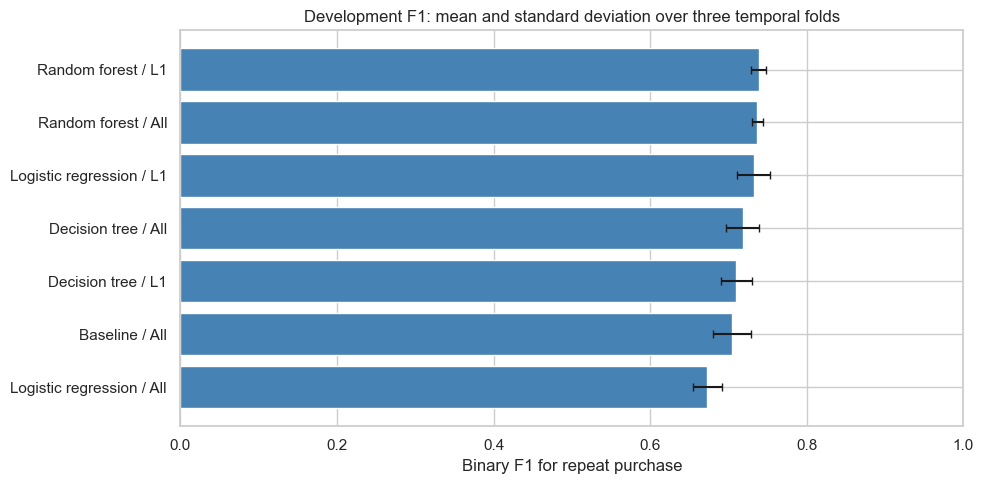

In [11]:
sns.set_theme(style="whitegrid")
res = summary.sort_values("mean")
labels = res["model"] + " / " + res["features"]
plt.figure(figsize=(10, 5))
plt.barh(labels, res["mean"], xerr=res["std"], color="steelblue", capsize=3)
plt.title("Development F1: mean and standard deviation over three temporal folds")
plt.xlabel("Binary F1 for repeat purchase")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## Choose the homework solution
We choose the classifier/feature-set combination with the largest mean inner
F1. The baseline remains a reference. This rule is applied before looking
at outer holdout performance.

Random forest with L1 has mean F1 0.7384 (fold standard deviation 0.0096),
compared with 0.7044 for the baseline. Forest without selection scores
0.7368: the 0.0016 difference is small and does not establish a reliable
performance improvement. The selected version offers a smaller input set.
Logistic regression also benefits from L1 here, while the tree does not.

In [12]:
choice = summary.loc[summary["model"] != "Baseline"].iloc[0]
name = choice["model"]
features = choice["features"]
print("Selected classifier:", name)
print("Feature set:", features)
print("Mean development F1:", round(choice["mean"], 4))

Selected classifier: Random forest
Feature set: L1
Mean development F1: 0.7384


## Fit on the full development period
Model selection is finished. We can now use the development matrix from Data
Preparation, whose transformations were fitted on those 5,024 purchases.
Its holdout counterpart will be used in Evaluation.

In [13]:
train = pd.read_csv("../data/prepared/train.csv", index_col="ID")
X_train = train.drop(columns=target)
y_train = train[target]

select = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                             max_iter=2000, random_state=42)
select.fit(X_train, y_train)
keep = np.abs(select.coef_[0]) > 0.000001
chosen = X_train.columns[keep].tolist()
print("L1 variables on full development:", len(chosen), "of", X_train.shape[1])

L1 variables on full development: 54 of 276


In [14]:
res = pd.Series(select.coef_[0], index=X_train.columns, name="coefficient")
res = res.loc[chosen]
res = res.loc[res.abs().sort_values(ascending=False).index]
res.head(15).round(3)

purchase_count_365d                                            1.210
island_Missing                                                 0.613
purchase_count_90d                                             0.512
country_or_region_Country CT10: Land of The Final Version      0.391
purchase_month_9                                               0.359
purchase_month_12                                             -0.272
purchase_month_11                                             -0.269
purchase_weekday_0                                             0.265
purchase_month_3                                              -0.222
prior_max_purchase_value                                       0.218
municipality_Municipality MU9: Council of Last Minute Edits    0.215
purchase_month_4                                              -0.211
spend_90d                                                      0.205
Total Desc_ Linha                                              0.203
postal_area_infrequent_sklearn    

These are coefficients of the L1 screening model, not causal effects or
importance scores for every classifier. Numeric inputs are standardised;
one-hot coefficients describe a category change. The final subset follows
the cross-validated choice, which may retain all inputs.

On full development, L1 retains 54 of 276 inputs, including `random_noise`.
This follows the fixed coefficient rule; it does not establish that this
supplied noise variable has stable signal. A targeted ablation inside
development is a useful extension for the final project.

In [15]:
if features == "L1":
    cols = chosen
else:
    cols = X_train.columns.tolist()

model = clone(models[name])
model.fit(X_train[cols], y_train)
print("Final development inputs:", len(cols))
print("random_noise retained:", "random_noise" in cols)

Final development inputs: 54
random_noise retained: True


## Save the comparison and the fitted development model
The model file connects Modeling to Evaluation. Deployment will clone its
settings and refit the chosen method on all eligible training purchases.
The final feature list is saved explicitly for review.

In [16]:
os.makedirs("../results", exist_ok=True)
scores.to_csv("../results/cv_results.csv", index=False)
summary.to_csv("../results/cv_summary.csv", index=False)
pd.Series(cols, name="feature").to_csv("../results/selected_features.csv", index=False)

obj = {"model": model, "columns": cols, "feature_mode": features,
       "model_name": name, "selector_c": 0.1, "training_ids": X_train.index.tolist()}
joblib.dump(obj, "../results/development_model.joblib")

['../results/development_model.joblib']

Next: [Evaluation](05_Evaluation.ipynb). The holdout has not been used to
choose the classifier, its features or its decision threshold.